# Non-sequential ray tracing

A sequential ray trace (`pyoptics.raytrace`,
notebook 001 (introduction to geometrical optics) onwards) knows the order of the surfaces in advance:
every ray goes from surface 1 to surface 2 to surface 3, and a ray that
misses a surface is simply lost. That is the right model for designing an
imaging lens, and the wrong one for everything that does not follow the
design path: the light reflected at every glass surface (ghosts, notebook 613
(flare and ghosts)), light scattered by a lens barrel, total internal
reflection in prisms and light pipes, or an LED in a reflector cup. In a
*non-sequential* trace the rays find their own way: at every step a ray
looks for the nearest face in its way, whatever face that is, and then
reflects, refracts, scatters or is absorbed there.

`pyoptics.nsrt` does this for a `Scene` of faces: analytic faces (planes,
spheres, conics, cylinders, cones, and every surface of `raytrace` with a
sag), triangle meshes from CAD solids, and whole lenses taken from a
`raytrace.System`. This notebook introduces the pieces on small examples:

1. a glass cube: one ray becomes a tree of rays, and the power is booked,
2. a prism retroreflector: total internal reflection and ray histories,
3. ray splitting versus Monte Carlo: exact answers and noise,
4. scattering models (BSDFs): Lambertian, Gaussian and ABg,
5. importance sampling: aiming scattered rays at what matters,
6. CAD solids: an LED reflector cup made with build123d, with properties
   per face.

Notebook 441 (stray light in Caldwell's lens) then uses all of it for the
ghosts and the mount scatter of a lithography lens.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import nsrt, bsdf
from pyoptics import raytrace as rt

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()

## 1. A glass cube

A scene is a list of faces in one frame (lengths in mm). Each face is
oriented: its normal points from the medium `media[0]` ("minus side") into
the medium `media[1]` ("plus side"). For the faces of a solid the normals
point outwards, so `media=(inside, outside)`. `nsrt.box()` makes the six
faces of a cuboid. Every face has a `FaceProperty`; the default,
`nsrt.fresnel()`, reflects and refracts with Fresnel's equations
(unpolarized) for the two indices: with the angles of incidence $\theta_i$ and
refraction $\theta_t$ ($n_i\sin\theta_i = n_t\sin\theta_t$),

$$r_s = \frac{n_i\cos\theta_i - n_t\cos\theta_t}{n_i\cos\theta_i + n_t\cos\theta_t}, \qquad
  r_p = \frac{n_t\cos\theta_i - n_i\cos\theta_t}{n_t\cos\theta_i + n_i\cos\theta_t}, \qquad
  R = \tfrac12\bigl(|r_s|^2 + |r_p|^2\bigr), \quad T = 1 - R .$$

A ray of weight $w$ that hits a face continues as a reflected ray of weight
$wR$ and a refracted ray of weight $wT$ (the sign of $r_p$ is a convention,
notebook 200 (interfaces and thin films); only $R$ enters here).

Five parallel rays hit a cube of glass (n = 1.5) at 35 degrees. In the
default mode `"split"`, every hit splits a ray into a reflected and a
refracted child with the Fresnel weights, so one ray becomes a tree. The
weights fall quickly (4 % per reflection at normal incidence), and
children below `min_weight` (relative to a source ray) go through Russian
roulette: they survive with the probability weight/threshold at the
threshold weight, which keeps the result unbiased. With `record=True` the
trace keeps the segments for plotting; `plot_rays()` draws them with the
opacity following the logarithm of the weight and the colour following
the last event (refracted, reflected, scattered).

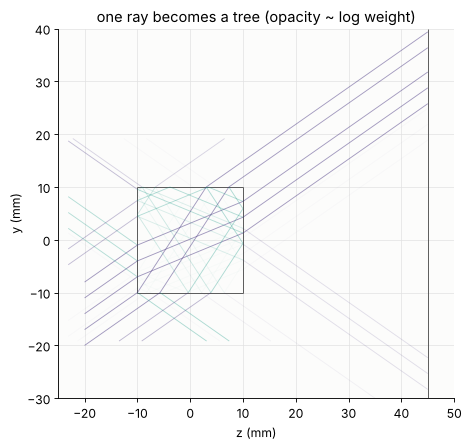

traced 77 ray segments in 12 steps
  absorbed  0.896686
  bulk      0.000000
  escaped   0.103314
  lost      0.000000
  total     1.000000
absorbed by the screen: 0.8967


In [2]:
scene = nsrt.Scene(wavelength=550e-6)
scene.add(nsrt.box((20, 20, 20), rotation=rt.rotation(0, 0, 0), media=(1.5, 1.0), label="cube"))
scene.add(nsrt.Rectangle(80, 80, position=(0, 0, 45), property=nsrt.absorber(),
                         label="screen", detector=True))

a = np.radians(35)
y0 = np.linspace(-6, 6, 5)
src = nsrt.RaySet(np.c_[np.zeros(5), y0 - 20*np.tan(a), np.full(5, -20.0)],
                  np.tile([0, np.sin(a), np.cos(a)], (5, 1)), np.full(5, 0.2))
res = scene.trace(src, min_weight=1e-6, record=True)

fig, ax = plt.subplots(figsize=(8, 6))
nsrt.plot_scene(scene, ax)
nsrt.plot_rays(res, ax, lw=0.8)
ax.set(xlim=(-25, 50), ylim=(-30, 40), xlabel="z (mm)", ylabel="y (mm)",
       title="one ray becomes a tree (opacity ~ log weight)")
plt.show()

print("traced {} ray segments in {} steps".format(res.n_rays_traced, res.generations))
for k, v in res.balance().items():
    print("  {:9s} {:.6f}".format(k, v))
print("absorbed by the screen: {:.4f}".format(res.absorbed_by("screen")))

`TraceResult.balance()` books where the power went: absorbed on faces,
absorbed in the bulk of absorbing media, escaped from the scene, and
"lost" (rays stopped after too many events). The total is 1 up to the
roulette noise. The screen is a *detector*: it records every hit with its
position, direction, weight and history. `Hits.paths()` groups the rays by
their sequence of reflections (and scatters) and ranks the groups by
power. Refractions are not listed, so "direct" means "refracted only".

In [3]:
h = res.hits["screen"]
print(h)
for power, n, path in h.paths(6):
    print("{:9.2e}  {:3d} rays  {}".format(power, n, path))

Hits('screen', 12 rays, power 0.8967)
 8.96e-01    5 rays  direct
 6.79e-04    2 rays  cube.+z R -> cube.+y R -> cube.-z R
 3.40e-04    1 rays  cube.+z R -> cube.-z R -> cube.+y R
 5.87e-05    1 rays  cube.+y R -> cube.+z R -> cube.-y R -> cube.-z R -> cube.+y R
 6.30e-07    1 rays  cube.+z R -> cube.-z R -> cube.+y R -> cube.+z R -> cube.-z R -> cube.-y R
 6.30e-07    1 rays  cube.+z R -> cube.+y R -> cube.-z R -> cube.+z R -> cube.-z R -> cube.-y R


## 2. A prism retroreflector and total internal reflection

The faces of solids can also come as triangle meshes. Planar faces are
exact as triangles, so a prism is a natural mesh: six vertices, eight
triangles, wound counterclockwise seen from outside (normals outwards).
Light entering the hypotenuse of a right angle prism is reflected twice
by total internal reflection at the legs and leaves antiparallel. TIR is
not a special case: Fresnel's equations give R = 1 beyond the critical
angle (41.8 degrees for n = 1.5; here the angle is 45 degrees).

outward normals: True


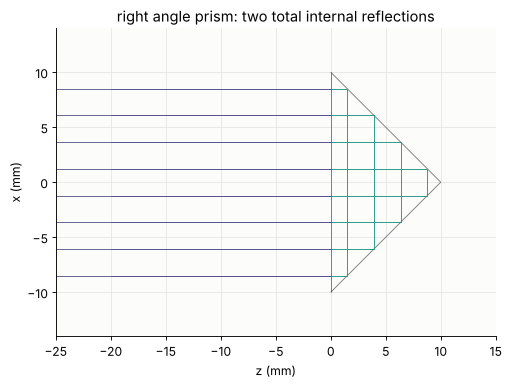

 0.92160  prism R -> prism R
 0.04000  prism R
 0.03686  prism R -> prism R -> prism R -> prism R -> prism R
 0.00147  prism R -> prism R -> prism R -> prism R -> prism R -> prism R -> prism R -> prism R
expected for the retro path (1 - R)**2 = 0.92160


In [4]:
n = 1.5
V = np.array([[-10, -15, 0], [10, -15, 0], [0, -15, 10], [-10, 15, 0], [10, 15, 0], [0, 15, 10]], float)
T = np.array([[0, 1, 2], [3, 5, 4], [0, 4, 1], [0, 3, 4], [1, 4, 5], [1, 5, 2], [0, 2, 5], [0, 5, 3]])
prism = nsrt.Mesh(V, T, properties=nsrt.fresnel(), media=(n, 1.0), labels=["prism"])
print("outward normals:", np.all(np.sum(prism.normals*(V[T].mean(1) - V.mean(0)), -1) > 0))

scene = nsrt.Scene()
scene.add(prism)
scene.add(nsrt.Rectangle(60, 60, position=(0, 0, -30), rotation=rt.rotation(np.pi, 0, 0),
                         property=nsrt.absorber(), label="back", detector=True))
x0 = np.linspace(-8.5, 8.5, 8)
src = nsrt.RaySet(np.c_[x0, np.zeros(8), np.full(8, -20.0)], np.tile([0, 0, 1.0], (8, 1)),
                  np.full(8, 1/8))
res = scene.trace(src, min_weight=1e-6, record=True)

fig, ax = plt.subplots(figsize=(8, 5))
nsrt.plot_scene(scene, ax, plane="xz")
nsrt.plot_rays(res, ax, plane="xz", lw=0.8)
ax.set(xlim=(-25, 15), ylim=(-14, 14), xlabel="z (mm)", ylabel="x (mm)",
       title="right angle prism: two total internal reflections")
plt.show()

R = ((n - 1)/(n + 1))**2
h = res.hits["back"]
for power, k, path in h.paths(4):
    print("{:8.5f}  {}".format(power, path))
print("expected for the retro path (1 - R)**2 = {:.5f}".format((1 - R)**2))

The strongest path is the retroreflection, with "prism R" twice (the TIR
bounces) and (1 - R)² of the power for the two passes through the
hypotenuse. Next is the plain Fresnel reflection at the hypotenuse, then
paths with an extra internal reflection there.

## 3. Splitting versus Monte Carlo

A plane parallel plate shows the two modes of the trace. Its incoherent
transmission, with all multiple reflections (the light bounces between the
two faces and each pass leaves a fraction $1-R$), is the geometric series

$$T_\mathrm{plate} = (1-R)^2\sum_{m=0}^\infty R^{2m} = \frac{(1-R)^2}{1-R^2} = \frac{1-R}{1+R}.$$ In split
mode every ray follows every channel down to the roulette threshold, so
already a single ray gives the answer to about that threshold. In
`mode="mc"` each ray picks *one* channel at random with the probability of
that channel (the absorbed part is booked and taken off the weight,
"implicit capture"). That is cheaper per ray but noisy: the error falls
as 1/sqrt(N). Splitting is the method for ghosts, which are weak but
deterministic; Monte Carlo wins where the number of paths explodes,
e.g. with many scatter events.

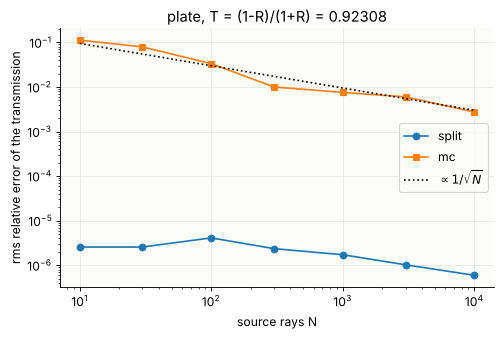

In [5]:
n = 1.5
R = ((n - 1)/(n + 1))**2
plate = nsrt.Scene()
plate.add(nsrt.ConicFace(np.inf, 30.0, media=(1.0, n), label="front"),
          nsrt.ConicFace(np.inf, 30.0, position=(0, 0, 5.0), media=(n, 1.0), label="back"),
          nsrt.Rectangle(100, 100, position=(0, 0, 20.0), property=nsrt.absorber(),
                         label="det", detector=True))
exact = (1 - R)/(1 + R)

Ns = [10, 30, 100, 300, 1000, 3000, 10000]
err = {"split": [], "mc": []}
for mode in err:
    for N in Ns:
        e = []
        for seed in range(12):
            src = nsrt.collimated_beam((0, 0, -10), (0, 0, 1), 1.0, N, rng=seed)
            r = plate.trace(src, mode=mode, min_weight=1e-3, rng=100 + seed)
            e.append(r.hits["det"].power - exact)
        err[mode].append(np.sqrt(np.mean(np.square(e))))

fig, ax = plt.subplots(figsize=(7, 4.2))
for mode, mk in (("split", "o-"), ("mc", "s-")):
    ax.loglog(Ns, np.array(err[mode])/exact, mk, label=mode)
ax.loglog(Ns, 0.3/np.sqrt(Ns), "k:", label=r"$\propto 1/\sqrt{N}$")
ax.set(xlabel="source rays N", ylabel="rms relative error of the transmission",
       title="plate, T = (1-R)/(1+R) = {:.5f}".format(exact))
ax.legend()
plt.show()

Split mode is exact up to the roulette below the threshold (1e-3 here:
the third order reflections, R⁴ ≈ 3e-6, are decided by roulette); Monte
Carlo needs a hundred times more rays for every digit.

## 4. Scattering models

Real surfaces scatter. `pyoptics.bsdf` describes scatter in direction
cosine space: a direction leaving the surface is beta, its projection onto
the tangent plane (|beta| is the sine of its angle to the normal), and the
specular direction is beta_0. The bidirectional scatter distribution
function (BSDF, 1/sr) is the scattered radiance per incident irradiance;
integrated over the unit disk of beta (the projected solid angle,
$\mathrm d\Omega\cos\theta = \mathrm d^2\beta$) it gives
the total integrated scatter TIS, the scattered fraction of the incident
power:

$$\mathrm{BSDF}(\boldsymbol\beta;\boldsymbol\beta_0) = \frac{\mathrm dL_s(\boldsymbol\beta)}{\mathrm dE_i}, \qquad
  \mathrm{TIS} = \int_{|\boldsymbol\beta| \le 1} \mathrm{BSDF}(\boldsymbol\beta;\boldsymbol\beta_0)\,\mathrm d^2\beta .$$ The models are shift invariant (Harvey): they depend on |beta -
beta_0| only, so a lobe keeps its shape and slides with the angle of
incidence, and the part that slides past |beta| = 1 is not scattered.

- `Lambertian(rho)`: BSDF = rho/pi, a perfectly matte surface (white
  paint, ground glass, and the diffuse floor of black coatings).
- `Gaussian(tis, sigma)`: a lobe of width sigma around the specular
  direction.
- `ABg(A, B, g)`: BSDF = A/(B + |beta - beta_0|^g), the standard fit of
  measured scatter of polished optics and black finishes: flat inside
  |beta - beta_0| < B^(1/g), falling with slope -g on a log-log plot
  outside.
- sums of models (`+`), e.g. `nsrt.black_anodized()` = 2 % Lambertian
  plus a broad ABg lobe plus 0.5 % specular (invented, plausible values).

A `FaceProperty` holds the specular R and T (None: Fresnel or a coating)
and the scatter models `brdf` (reflection) and `btdf` (transmission).

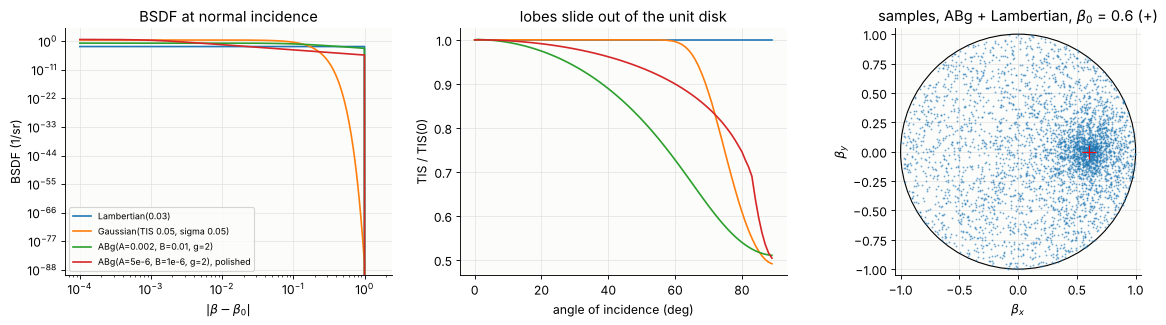

black_anodized  specular R 0.005, TIS (reflection) 0.049
black_paint     specular R 0.000, TIS (reflection) 0.030
machined_metal  specular R 0.600, TIS (reflection) 0.239
ground_glass    specular R 0.000, TIS (reflection) 0.040


In [6]:
models = {"Lambertian(0.03)": bsdf.Lambertian(0.03),
          "Gaussian(TIS 0.05, sigma 0.05)": bsdf.Gaussian(0.05, 0.05),
          "ABg(A=0.002, B=0.01, g=2)": bsdf.ABg(A=0.002, B=0.01, g=2.0),
          "ABg(A=5e-6, B=1e-6, g=2), polished": bsdf.ABg(A=5e-6, B=1e-6, g=2.0)}
rho = np.geomspace(1e-4, 1.5, 400)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for name, m in models.items():
    b = np.c_[rho, 0*rho]
    axs[0].loglog(rho, m.bsdf(b, np.zeros_like(b)), label=name)
    th = np.radians(np.linspace(0, 89, 90))
    axs[1].plot(np.degrees(th), m.tis(np.sin(th))/m.tis(np.array([0.0]))[0], label=name)
axs[0].set(xlabel=r"$|\beta - \beta_0|$", ylabel="BSDF (1/sr)", title="BSDF at normal incidence")
axs[1].set(xlabel="angle of incidence (deg)", ylabel="TIS / TIS(0)",
           title="lobes slide out of the unit disk")
axs[0].legend(fontsize=8)

rng = np.random.default_rng(0)
b0 = np.tile([0.6, 0.0], (4000, 1))
ab = bsdf.ABg(A=0.002, B=0.01, g=2.0) + bsdf.Lambertian(0.02)
s = ab.sample(b0, rng)
axs[2].plot(s[:, 0], s[:, 1], ".", ms=1.5, alpha=0.5)
axs[2].add_patch(plt.Circle((0, 0), 1, fill=False, color="k"))
axs[2].plot([0.6], [0], "r+", ms=12)
axs[2].set(aspect="equal", xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), xlabel=r"$\beta_x$",
           ylabel=r"$\beta_y$", title=r"samples, ABg + Lambertian, $\beta_0$ = 0.6 (+)")
plt.tight_layout()
plt.show()
for name in ("black_anodized", "black_paint", "machined_metal", "ground_glass"):
    p = getattr(nsrt, name)()
    tis = p.brdf.tis(np.array([0.0]))[0]
    print("{:15s} specular R {:.3f}, TIS (reflection) {:.3f}".format(name, p.R if p.R is not None else np.nan, tis))

## 5. Importance sampling

A scattered ray goes into a random direction drawn from the BSDF. If the
detector subtends a small solid angle, almost all of these rays miss it.
`trace(targets=[...])` aims a fraction `aim_fraction` of the scattered
rays at target disks (the detector, the next lens, an aperture) and
weights every scattered ray with BSDF/pdf, where pdf is the mixture of the
two sampling strategies,

$$w_\mathrm{out} = w_\mathrm{in}\,\frac{\mathrm{BSDF}(\boldsymbol\beta)}{(1-a)\,p_\mathrm{BSDF}(\boldsymbol\beta) + a\,p_\mathrm{target}(\boldsymbol\beta)},$$

with the aim fraction $a$ and the densities (per projected solid angle) of
the two strategies (multiple importance sampling with the balance
heuristic, Veach and Guibas). The mean stays the same, the noise drops.

The test case: a collimated beam on a small Lambertian spot (reflectance
rho = 0.8), and a coaxial detector disk of radius a at the height h. The
detector receives rho a²/(a² + h²) of the power (the view factor of a disk
from a point on its axis).

In [7]:
rho, a, hgt = 0.8, 2.0, 30.0
scene = nsrt.Scene()
scene.add(nsrt.Rectangle(4, 4, property=nsrt.diffuse(rho), label="plate"))
det = scene.add(nsrt.ConicFace(np.inf, a, position=(0, 0, hgt), property=nsrt.absorber(),
                               label="det", detector=True))
exact = rho*a**2/(a**2 + hgt**2)
target = nsrt.Target.from_face(det)

out = {"BSDF sampling": [], "aimed (50 %)": []}
for seed in range(30):
    src = nsrt.collimated_beam((0, 0, 5), (0, 0, -1), 0.01, 2000, rng=seed)
    out["BSDF sampling"].append(scene.trace(src, rng=seed).hits["det"].power)
    out["aimed (50 %)"].append(scene.trace(src, rng=seed, targets=[target],
                                           aim_fraction=0.5).hits["det"].power)
print("exact {:.5f}".format(exact))
for k, v in out.items():
    v = np.array(v)
    print("{:14s} mean {:.5f}, rms error {:.1%} with 2000 rays".format(k, v.mean(),
                                                                      np.std(v)/exact))

exact 0.00354
BSDF sampling  mean 0.00321, rms error 36.0% with 2000 rays
aimed (50 %)   mean 0.00354, rms error 2.0% with 2000 rays


Both estimates are unbiased; aiming cuts the noise by more than an order
of magnitude, i.e. it saves a factor of several hundred in rays. In a
real system the gain depends on how directly the target can be reached:
light scattered off a spacer deep inside a lens has to pass several lenses
before the image, and aiming at a single disk helps less (notebook 441,
stray light in Caldwell's lens).

## 6. CAD solids: an LED in a reflector cup

Mechanical parts come from CAD. `Scene.add_shapes()` tessellates
[build123d](https://github.com/gumyr/build123d) solids into a triangle
mesh, `Scene.add_step()` reads STEP files and `Scene.add_stl()` STL files.
Every solid becomes one face of the scene with the solid's `label`; with
`per_face=True` every B-rep face of the solid becomes a face of its own
("cup.f0", "cup.f1", ...). Properties (and media for transparent solids)
are assigned by label in one of three ways:

- one property for all solids: `property=nsrt.black_anodized()`,
- a dict by label: `{"barrel": nsrt.black_anodized(), "spacer_*":
  nsrt.machined_metal(), "*": nsrt.absorber()}`, with exact labels, label
  prefixes ending in `*` (the longest match wins) and `"*"` for the rest,
- a function `f(label, shape)` that gets the label and the build123d solid,
  or with `per_face=True` the build123d `Face`, so that it can decide by
  the face's geometry (`face.geom_type`, `face.center()`,
  `face.normal_at()`, ...). None means the default (`absorber()`).

The example: a reflector cup made as a solid with build123d, a cylinder
with a conical cavity. Only the cone (the inside of the cup) gets an
optical finish, all other faces are black. An LED (a Lambertian disk of
1 mm diameter) sits at the bottom of the cavity, and a plano-convex lens
(analytic faces) collimates the light onto a screen 150 mm away.

In [8]:
import build123d as bd

r_bottom, r_top, depth = 2.0, 9.0, 8.0
cup = (bd.Solid.make_cylinder(11.0, depth + 1.0, bd.Plane(origin=(0, 0, -1.0)))
       - bd.Solid.make_cone(r_bottom, r_top, depth, bd.Plane(origin=(0, 0, 0))))
cup.label = "cup"
print([(k, f.geom_type.name) for k, f in enumerate(cup.faces())])


def build(finish):
    "Scene with the cup finished on its conical face, the lens and the screen."
    def by_face(label, face):
        return finish if face.geom_type.name == "CONE" else nsrt.black_paint()
    scene = nsrt.Scene(wavelength=550e-6)
    if finish is not None:
        scene.add_shapes([cup], property=by_face, per_face=True, tolerance=0.005)
    # plano-convex lens, f about 18 mm, n = 1.5
    z0 = 12.0
    scene.add(nsrt.ConicFace(np.inf, 11.0, position=(0, 0, z0), media=(1.0, 1.5), label="lens:front"),
              nsrt.ConicFace(-9.0, 9.0, position=(0, 0, z0 + 7.0), media=(1.5, 1.0), label="lens:back"),
              nsrt.Cylinder(11.0, z0, z0 + 7.0 + 9.0 - np.sqrt(81 - 0.0), property=nsrt.absorber(),
                            label="lens:rim"),
              nsrt.ConicFace(np.inf, 11.0, r_min=9.0, position=(0, 0, z0 + 7.0), property=nsrt.absorber(),
                             label="lens:flat"))
    scene.add(nsrt.Rectangle(200, 200, position=(0, 0, 160.0), property=nsrt.absorber(),
                             label="screen", detector=True))
    return scene


led = nsrt.lambertian_source((0, 0, 0.01), (0, 0, 1), 0.5, 100000, rng=1)
cases = {"no cup": None, "mirror cup (R = 0.9)": nsrt.mirror(0.9),
         "white cup (Lambertian 0.95)": nsrt.diffuse(0.95)}
results = {}
for name, finish in cases.items():
    sc = build(finish)
    t = time.time()
    results[name] = (sc, sc.trace(led, mode="mc", min_weight=1e-2, rng=2))
    print("{:28s} traced in {:.1f} s, on the screen {:.3f}".format(
        name, time.time() - t, results[name][1].hits["screen"].power))

[(0, 'CYLINDER'), (1, 'PLANE'), (2, 'PLANE'), (3, 'CONE'), (4, 'PLANE')]


no cup                       traced in 0.4 s, on the screen 0.236


mirror cup (R = 0.9)         traced in 1.2 s, on the screen 0.438


white cup (Lambertian 0.95)  traced in 1.6 s, on the screen 0.413


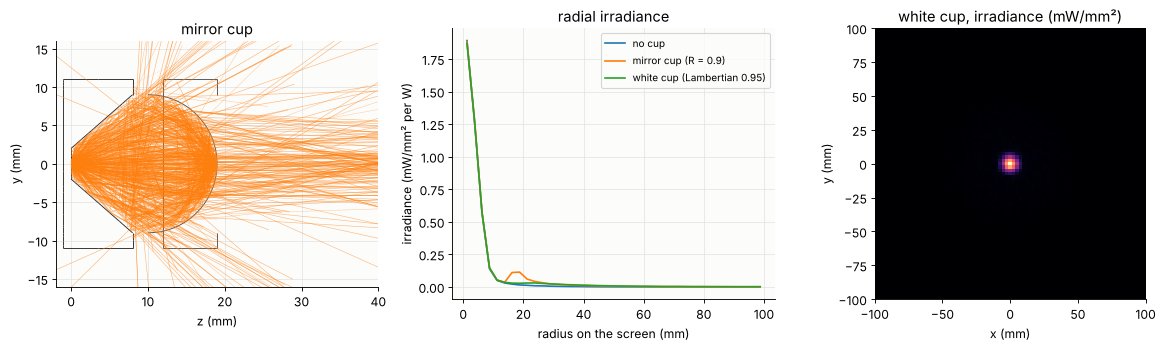

white cup: where the power goes
  screen       0.413
  lens:rim     0.106
  cup.f1       0.075
  cup.f4       0.054
  cup.f3       0.050
  lens:flat    0.029


In [9]:
sc, r = build(nsrt.mirror(0.9)), None
r = sc.trace(nsrt.lambertian_source((0, 0, 0.01), (0, 0, 1), 0.5, 300, rng=3), mode="mc",
             record=True, rng=4)
fig = plt.figure(figsize=(15, 4.5))
ax = fig.add_subplot(1, 3, 1)
nsrt.plot_scene(sc, ax, mesh_alpha=1.0)
nsrt.plot_rays(r, ax, color="C1", lw=0.5, alpha=0.6)
ax.set(xlim=(-2, 40), ylim=(-16, 16), xlabel="z (mm)", ylabel="y (mm)", title="mirror cup")

ax = fig.add_subplot(1, 3, 2)
for name, (sc, res) in results.items():
    h = res.hits["screen"]
    rr = np.hypot(h.points[:, 0], h.points[:, 1])
    edges = np.linspace(0, 100, 41)
    P, _ = np.histogram(rr, edges, weights=h.weights)
    E = P/(np.pi*np.diff(edges**2))
    ax.plot(0.5*(edges[1:] + edges[:-1]), E*1e3, label=name)
ax.set(xlabel="radius on the screen (mm)", ylabel="irradiance (mW/mm² per W)",
       title="radial irradiance")
ax.legend(fontsize=9)

ax = fig.add_subplot(1, 3, 3)
E, xe, ye = results["white cup (Lambertian 0.95)"][1].hits["screen"].irradiance(
    81, ((-100, 100), (-100, 100)))
ax.imshow(E.T*1e3, extent=(xe[0], xe[-1], ye[0], ye[-1]), origin="lower", cmap="magma")
ax.set(xlabel="x (mm)", ylabel="y (mm)", title="white cup, irradiance (mW/mm²)")
ax.grid(False)
plt.tight_layout()
plt.show()

res = results["white cup (Lambertian 0.95)"][1]
print("white cup: where the power goes")
for lab, p in res.summary(6):
    print("  {:12s} {:.3f}".format(lab, p))

The specular cup sends the wide-angle LED light through the lens as a
second, larger beam around the direct one; the white cup returns light in
all directions, part of it back onto the LED and cup, and adds a broad
halo. `TraceResult.summary()` lists where the power was absorbed, here per
B-rep face of the cup ("cup.f1" is the cone).

The same works for any STEP file: `scene.add_step("housing.step",
property={...})` reads all solids with their names from the file.

## Summary

- `nsrt.Scene` holds faces: analytic (`ConicFace`, `SagFace`, `Rectangle`,
  `Cylinder`, `Cone`, `Sphere`, `box()`), meshes (`Mesh`, `add_shapes()`,
  `add_step()`, `add_stl()`) and complete lenses (`add_system()`).
- Faces carry the media on both sides and a `FaceProperty`: Fresnel or
  coatings, fixed R and T, absorbers, and the scattering models of
  `pyoptics.bsdf`. CAD solids get properties by label, label prefix or per
  B-rep face.
- `trace()` splits rays (exact for ghosts) or samples one channel (Monte
  Carlo), with Russian roulette, importance sampling of scatter and a
  history of every ray: `Hits.paths()`, `Hits.mask()` and
  `Hits.irradiance()` analyse the detector hits.

In [10]:
print("notebook run time {:.0f} s".format(time.time() - t_start))

notebook run time 16 s
